In [1]:
# Praktikum 3.1 - Persiapan Library
!pip install imbalanced-learn -q

import numpy as np
import pandas as pd
from sklearn.impute import KNNImputer
from sklearn.ensemble import IsolationForest
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score, classification_report

import warnings
warnings.filterwarnings('ignore')

print("✅ Semua library berhasil diimport")

✅ Semua library berhasil diimport


In [2]:
# Praktikum 3.2 - Import Dataset Sintetis
from sklearn.datasets import make_classification

# Dataset sintetis untuk simulasi (imbalance 95:5)
X, y = make_classification(
    n_samples=2000,
    n_features=8,
    weights=[0.95, 0.05],
    random_state=42
)

df = pd.DataFrame(X, columns=[f"fitur_{i}" for i in range(8)])
df["target"] = y

# Simulasikan missing values (~5%)
rng = np.random.default_rng(42)
mask = rng.random(df.shape) < 0.05
df_missing = df.mask(pd.DataFrame(mask, columns=df.columns))

print("Distribusi kelas target:")
print(df["target"].value_counts())
print("\nJumlah missing values per kolom:")
print(df_missing.isnull().sum())

Distribusi kelas target:
target
0    1888
1     112
Name: count, dtype: int64

Jumlah missing values per kolom:
fitur_0    101
fitur_1     89
fitur_2     81
fitur_3    106
fitur_4    109
fitur_5     98
fitur_6    100
fitur_7     97
target     106
dtype: int64


In [3]:
# Praktikum 3.3 - Imputasi & Deteksi Outlier
imputer = KNNImputer(n_neighbors=5)
fitur_cols = [c for c in df.columns if c.startswith("fitur")]

df_imputed = df_missing.copy()
df_imputed[fitur_cols] = imputer.fit_transform(df_missing[fitur_cols])

# Deteksi outlier dengan Isolation Forest
iso = IsolationForest(contamination=0.02, random_state=42)
df_imputed["is_outlier"] = iso.fit_predict(df_imputed[fitur_cols])

print("Jumlah outlier terdeteksi:", (df_imputed["is_outlier"] == -1).sum())
print("\nMissing values setelah imputasi:", df_imputed[fitur_cols].isnull().sum().sum())

Jumlah outlier terdeteksi: 40

Missing values setelah imputasi: 0


In [7]:
# Praktikum 3.4 - Training dengan & tanpa SMOTE
from sklearn.impute import SimpleImputer

# 1. Buang baris yang targetnya (y) kosong (NaN)
df_imputed = df_imputed.dropna(subset=["target"])

# 2. Ambil fitur & target
X = df_imputed[fitur_cols]
y = df_imputed["target"]

# 3. SAFETY NET: Pastikan tidak ada NaN tersisa di fitur (X)
imputer_final = SimpleImputer(strategy='mean')
X_clean = imputer_final.fit_transform(X)

# 4. Split data (menggunakan X_clean dan y yang sudah bersih)
X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y, test_size=0.2, stratify=y, random_state=42
)

# (a) Tanpa penanganan imbalance
model_base = LogisticRegression(max_iter=1000).fit(X_train, y_train)

# (b) Dengan SMOTE (HANYA pada train set!)
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)
model_smote = LogisticRegression(max_iter=1000).fit(X_train_sm, y_train_sm)

print("Distribusi y_train sebelum SMOTE:", dict(pd.Series(y_train).value_counts()))
print("Distribusi y_train setelah SMOTE :", dict(pd.Series(y_train_sm).value_counts()))

Distribusi y_train sebelum SMOTE: {0.0: np.int64(1433), 1.0: np.int64(82)}
Distribusi y_train setelah SMOTE : {0.0: np.int64(1433), 1.0: np.int64(1433)}


In [8]:
# Praktikum 3.5 - Evaluasi Model
for nama, model in [("Baseline (tanpa SMOTE)", model_base),
                    ("Dengan SMOTE", model_smote)]:
    y_pred = model.predict(X_test)
    print(f"--- {nama} ---")
    print("Akurasi :", round(accuracy_score(y_test, y_pred), 3))
    print("F1-Score:", round(f1_score(y_test, y_pred), 3))
    print(classification_report(y_test, y_pred, digits=3))
    print()

--- Baseline (tanpa SMOTE) ---
Akurasi : 0.953
F1-Score: 0.308
              precision    recall  f1-score   support

         0.0      0.955     0.997     0.975       358
         1.0      0.800     0.190     0.308        21

    accuracy                          0.953       379
   macro avg      0.877     0.594     0.642       379
weighted avg      0.946     0.953     0.938       379


--- Dengan SMOTE ---
Akurasi : 0.836
F1-Score: 0.367
              precision    recall  f1-score   support

         0.0      0.990     0.835     0.906       358
         1.0      0.234     0.857     0.367        21

    accuracy                          0.836       379
   macro avg      0.612     0.846     0.637       379
weighted avg      0.948     0.836     0.876       379




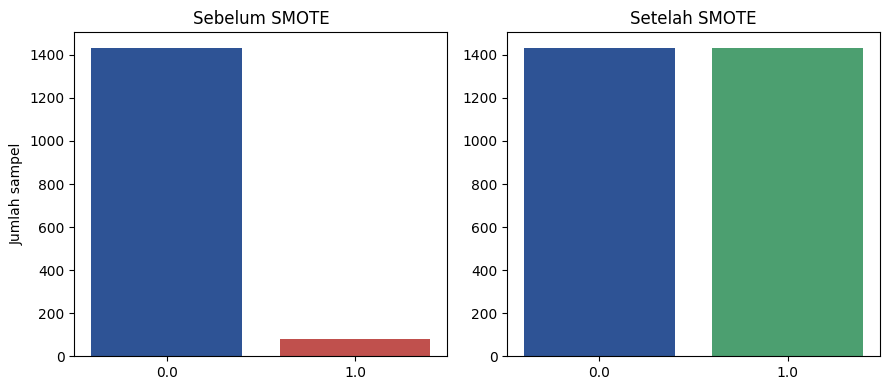

In [9]:
# Praktikum 3.6 - Visualisasi distribusi kelas
import matplotlib.pyplot as plt

before = y_train.value_counts().sort_index()
after  = pd.Series(y_train_sm).value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].bar(before.index.astype(str), before.values,
            color=["#2E5395", "#C0504D"])
axes[0].set_title("Sebelum SMOTE")
axes[0].set_ylabel("Jumlah sampel")

axes[1].bar(after.index.astype(str), after.values,
            color=["#2E5395", "#4C9F70"])
axes[1].set_title("Setelah SMOTE")

plt.tight_layout()
plt.show()